1.2247448713915892


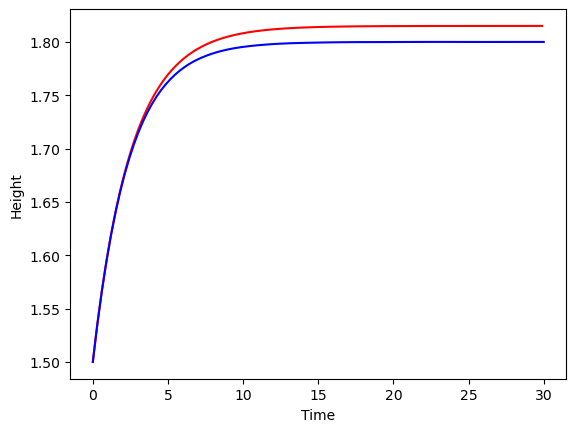

In [32]:
# FIRST ORDER SYSTEM - Step change
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.integrate import odeint

## ABHA'S CODE - Linear approximate ##
y0 = [0] #initial deviation
h_s1 = 1.5 #initial steady state height
f_i = 1.5 #initial steady state flow rate
c = 0.1 #equal to deviation
k = f_i/np.sqrt(h_s1)
A = 1.2
R = 2*(h_s1**0.5)/k
t_span = (0,30)
def model(t, H):
    dHbydt = (c*f_i/A) - (H/(R*A)) #if Fi = c (deviation variable)
    return dHbydt
sol = solve_ivp(model, t_span, y0, t_eval = np.linspace(0,30,100))
 ## VGG's CODE - Non linear model ##
tstop=30
tinc=0.1
t = np.arange(0.,tstop,tinc) ## initializing arrays for time
#
#initializing array of level and flow in
hts=1.5             #initial steady state value
fins=1.5            #initial steady state flowrate in and out
area=1.2            #cross section area of vessel
k=fins/np.sqrt(hts) #flow-level relation constant fo=k.sqrt(ht)
print(k)
# bundle parameters for ODE solver
params=[hts,fins,area,k] 
#
#defining derivatives from the ODE for 10% step change in input flow
def flevel(ht,t,params):
    fin=1.1*fins
    level=ht
    dhdt=(fin/area)-k*np.sqrt(level)/area
    #|print(t,level,dhdt)
    return dhdt
#
#define initial values of level
ht0=hts
#
# calling odeint; the ODE solver
ht=odeint(flevel, ht0, t, args=(params,))
# plotting the data

plt.plot(t,ht,'r')

h1 = ht.flatten()
plt.plot(sol.t, sol.y[0] + h_s1,'b')
plt.xlabel('Time')
plt.ylabel('Height')
plt.show()

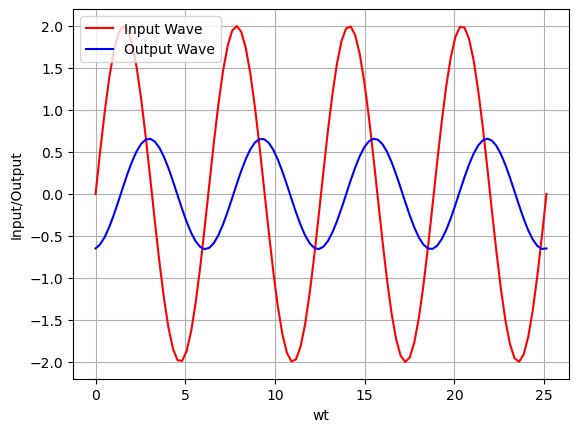

In [9]:
#First Order System - Sinusoidal input wave 
import numpy as np
import matplotlib.pyplot as plt
t = np.linspace(0, 4*np.pi, 100)
w = 2
A = 2
Kp = 2
tau = 3
X = A*np.sin(w*t)
amp = Kp/np.sqrt(1 + (w*tau)**2)
phi = np.arctan(-w*tau)
Y = amp*A*np.sin(w*t + phi)
plt.plot(w*t, X, 'r', label = "Input Wave")
plt.plot(w*t, Y, 'b', label = "Output Wave")
plt.grid()
plt.xlabel('wt')
plt.ylabel('Input/Output')
plt.legend()
plt.show()